# 05 Categorical History Features

Starting from the 04.5 reference dataset, this notebook adds three historical summaries for each of the 11 categorical variables: number of observed states, number of state changes, and whether the last observed state changed. Continuous aggregations and model settings remain fixed.


In [7]:
from pathlib import Path

def find_project_root() -> Path:
    """Use the parent of the notebook working directory as the project root."""
    project_root = Path.cwd().resolve().parent
    if not (project_root / 'data').is_dir():
        raise FileNotFoundError(
            "Expected the project data directory one level above the current working directory."
        )
    return project_root

import json, platform, time
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.ipc as ipc
import pyarrow.feather as feather
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
print('Python:', platform.python_version())
print('LightGBM:', lgb.__version__)


Python: 3.10.19
LightGBM: 4.7.0


### 1. Define the feature

The experiment creates 33 columns in total:

- `nunique`: count of distinct non-missing historical states;
- `num_changes`: count of transitions between adjacent non-missing observations;
- `last_changed`: whether the final two non-missing states differ.

These features summarize stability and transition behavior while preserving the existing `*_last` categorical values.


In [ ]:
ROOT = find_project_root()
STEP_DIR = ROOT / '05_categorical_features'
BASE_DATA = ROOT / '04.5_temporal_refined' / 'train_aggregated_temporal_refined.feather'
MONTHLY_DATA = ROOT / 'data' / 'train_data_float16_zstd.feather'
PREVIOUS_METRICS = ROOT / '04.5_temporal_refined' / 'temporal_refined_metrics.json'
OUTPUT_DATA = STEP_DIR / 'train_aggregated_temporal_categorical.feather'
MODEL_PATH = STEP_DIR / 'lightgbm_temporal_categorical.txt'
IMPORTANCE_PATH = STEP_DIR / 'temporal_categorical_feature_importance.csv'
PREDICTION_PATH = STEP_DIR / 'temporal_categorical_validation_predictions.parquet'
METRICS_PATH = STEP_DIR / 'temporal_categorical_metrics.json'

CATEGORICAL_VARIABLES = ['B_30','B_38','D_114','D_116','D_117','D_120','D_126','D_63','D_64','D_66','D_68']
FEATURE_TYPES = ['nunique', 'num_changes', 'last_changed']
NEW_FEATURES = [f'{v}_{kind}' for v in CATEGORICAL_VARIABLES for kind in FEATURE_TYPES]
print('Categorical variables:', len(CATEGORICAL_VARIABLES))
print('New features:', len(NEW_FEATURES))
print(NEW_FEATURES)


Categorical variables: 11
New features: 33
['B_30_nunique', 'B_30_num_changes', 'B_30_last_changed', 'B_38_nunique', 'B_38_num_changes', 'B_38_last_changed', 'D_114_nunique', 'D_114_num_changes', 'D_114_last_changed', 'D_116_nunique', 'D_116_num_changes', 'D_116_last_changed', 'D_117_nunique', 'D_117_num_changes', 'D_117_last_changed', 'D_120_nunique', 'D_120_num_changes', 'D_120_last_changed', 'D_126_nunique', 'D_126_num_changes', 'D_126_last_changed', 'D_63_nunique', 'D_63_num_changes', 'D_63_last_changed', 'D_64_nunique', 'D_64_num_changes', 'D_64_last_changed', 'D_66_nunique', 'D_66_num_changes', 'D_66_last_changed', 'D_68_nunique', 'D_68_num_changes', 'D_68_last_changed']


### 2. Stream categorical histories

Only customer ID, statement date, and the 11 categorical variables are read from monthly data. 


In [9]:
def aggregate_categorical_history(frame):
    customer_index = pd.Index(frame['customer_ID'].drop_duplicates(), name='customer_ID')
    result = pd.DataFrame(index=customer_index)
    grouped = frame.groupby('customer_ID', sort=False, observed=True)

    for variable in CATEGORICAL_VARIABLES:
        result[f'{variable}_nunique'] = grouped[variable].nunique(dropna=True).reindex(customer_index).astype('int8')
        observed = frame[['customer_ID', variable]].dropna(subset=[variable]).copy()
        if observed.empty:
            result[f'{variable}_num_changes'] = np.int8(0)
            result[f'{variable}_last_changed'] = np.int8(0)
            continue
        previous = observed.groupby('customer_ID', sort=False)[variable].shift(1)
        observed['_changed'] = previous.notna() & observed[variable].ne(previous)
        changes = observed.groupby('customer_ID', sort=False)['_changed'].sum()
        result[f'{variable}_num_changes'] = changes.reindex(customer_index, fill_value=0).astype('int8')
        last_rows = observed.groupby('customer_ID', sort=False).tail(1).set_index('customer_ID')
        result[f'{variable}_last_changed'] = last_rows['_changed'].reindex(customer_index, fill_value=False).astype('int8')

    return result.reset_index()

parts, audit_parts, carry = [], [], None
written_ids = set()
sample_ids = set(pd.read_feather(BASE_DATA, columns=['customer_ID'])['customer_ID'].sample(20, random_state=42).astype('int64'))
started = time.perf_counter()
with pa.memory_map(str(MONTHLY_DATA), 'r') as source:
    reader = ipc.open_file(source)
    selected = ['customer_ID', 'S_2', *CATEGORICAL_VARIABLES]
    indices = [reader.schema.get_field_index(c) for c in selected]
    assert min(indices) >= 0
    for batch_number in range(reader.num_record_batches):
        frame = reader.get_batch(batch_number).select(indices).to_pandas()
        if carry is not None:
            frame = pd.concat([carry, frame], ignore_index=True)
        assert frame.groupby('customer_ID', sort=False)['S_2'].apply(lambda x: x.is_monotonic_increasing).all()
        last_customer = frame['customer_ID'].iloc[-1]
        carry = frame[frame['customer_ID'] == last_customer].copy()
        complete = frame[frame['customer_ID'] != last_customer].copy()
        if len(complete):
            current_ids = set(complete['customer_ID'].unique())
            assert not current_ids.intersection(written_ids)
            parts.append(aggregate_categorical_history(complete))
            audit_parts.append(complete[complete['customer_ID'].isin(sample_ids)].copy())
            written_ids.update(current_ids)
        if (batch_number + 1) % 10 == 0 or batch_number + 1 == reader.num_record_batches:
            print(f'batch {batch_number + 1}/{reader.num_record_batches}: {len(written_ids):,} customers')
if carry is not None and len(carry):
    parts.append(aggregate_categorical_history(carry))
    audit_parts.append(carry[carry['customer_ID'].isin(sample_ids)].copy())
    written_ids.add(int(carry['customer_ID'].iloc[0]))
categorical_history = pd.concat(parts, ignore_index=True)
generation_seconds = time.perf_counter() - started
print(f'Generated: {categorical_history.shape}; time: {generation_seconds:.1f} sec')


batch 10/56: 82,974 customers
batch 20/56: 165,818 customers
batch 30/56: 248,848 customers
batch 40/56: 331,852 customers
batch 50/56: 414,807 customers
batch 56/56: 458,912 customers
Generated: (458913, 34); time: 41.2 sec


### 3. Merge and validate

The new history table is joined one-to-one with the 04.5 reference data and saved separately. Validation checks customer uniqueness, row preservation, expected columns, merge completeness, and sample calculations against raw monthly histories.


In [10]:
base = pd.read_feather(BASE_DATA)
assert base['customer_ID'].is_unique and categorical_history['customer_ID'].is_unique
assert len(base) == len(categorical_history) == len(written_ids)
data = base.merge(categorical_history, on='customer_ID', how='left', validate='one_to_one', sort=False)
assert len(data) == len(base) and data['customer_ID'].is_unique
assert not data[NEW_FEATURES].isna().any().any()
assert data.shape[1] == 1057

audit = pd.concat(audit_parts, ignore_index=True).sort_values(['customer_ID','S_2'])
lookup = categorical_history.set_index('customer_ID')
assert audit['customer_ID'].nunique() == 20
for customer_id, history in audit.groupby('customer_ID', sort=False):
    row = lookup.loc[customer_id]
    for variable in CATEGORICAL_VARIABLES:
        values = history[variable].dropna().to_numpy()
        expected_nunique = len(np.unique(values))
        expected_changes = int(np.sum(values[1:] != values[:-1])) if len(values) > 1 else 0
        expected_last_changed = int(values[-1] != values[-2]) if len(values) > 1 else 0
        assert row[f'{variable}_nunique'] == expected_nunique
        assert row[f'{variable}_num_changes'] == expected_changes
        assert row[f'{variable}_last_changed'] == expected_last_changed

feather.write_feather(pa.Table.from_pandas(data, preserve_index=False), OUTPUT_DATA, compression='zstd', compression_level=6, chunksize=65_536, version=2)
print('Checks passed for all rows plus 20-customer manual recomputation.')
print(f'Saved: {OUTPUT_DATA} ({OUTPUT_DATA.stat().st_size / 2**30:.2f} GiB)')
print('Final model feature count:', data.shape[1] - 2)


Checks passed for all rows plus 20-customer manual recomputation.
Saved: /Users/amberjiang/Desktop/AMEX/05_categorical_features/train_aggregated_temporal_categorical.feather (0.91 GiB)
Final model feature count: 1055


### 4. Train the model

The same split, categorical declarations, LightGBM parameters, and early-stopping rule are reused. The only change is the addition of 33 category-history columns, preserving a fair ablation-style comparison.


In [11]:
def amex_metric(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.int8); y_pred = np.asarray(y_pred, dtype=np.float64)
    weights = np.where(y_true == 0, 20.0, 1.0)
    order = np.argsort(-y_pred, kind='mergesort'); yy, ww = y_true[order], weights[order]
    top = np.cumsum(ww) <= .04 * ww.sum()
    top_four = (yy[top] * ww[top]).sum() / (y_true * weights).sum()
    def gini(pred):
        idx = np.argsort(-pred, kind='mergesort'); sy, sw = y_true[idx], weights[idx]
        return np.sum((np.cumsum(sy * sw) / np.sum(sy * sw) - np.cumsum(sw) / np.sum(sw)) * sw)
    return .5 * (gini(y_pred) / gini(y_true) + top_four)

customer_ids = data['customer_ID'].copy(); y = data['target'].astype('int8').copy()
X = data.drop(columns=['customer_ID','target']).copy()
X['S_2_last'] = (pd.to_datetime(X['S_2_last']) - pd.Timestamp('2018-03-01')).dt.days.astype('int16')
categorical_features = [f'{c}_last' for c in CATEGORICAL_VARIABLES]
for c in categorical_features: X[c] = X[c].astype('category')
indices = np.arange(len(X))
train_idx, valid_idx = train_test_split(indices, train_size=.70, test_size=.30, random_state=42, stratify=y)
y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]
assert X.shape[1] == 1055
model = lgb.LGBMClassifier(objective='binary', n_estimators=1500, learning_rate=.03, num_leaves=31, max_depth=-1, min_child_samples=100, subsample=.8, colsample_bytree=.8, reg_lambda=1.0, max_bin=127, random_state=42, n_jobs=4, verbosity=-1)
started = time.perf_counter()
model.fit(X.iloc[train_idx], y_train, eval_set=[(X.iloc[valid_idx], y_valid)], eval_metric='auc', categorical_feature=categorical_features, callbacks=[lgb.early_stopping(100, verbose=True), lgb.log_evaluation(50)])
training_seconds = time.perf_counter() - started
probability = model.predict_proba(X.iloc[valid_idx], num_iteration=model.best_iteration_)[:,1]
result = {'roc_auc': float(roc_auc_score(y_valid, probability)), 'amex_metric': float(amex_metric(y_valid, probability)), 'best_iteration': int(model.best_iteration_), 'training_seconds': float(training_seconds), 'feature_count': int(X.shape[1])}
result


/opt/anaconda3/envs/cs178/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[50]	valid_0's auc: 0.951505	valid_0's binary_logloss: 0.288579
[100]	valid_0's auc: 0.955591	valid_0's binary_logloss: 0.243123
[150]	valid_0's auc: 0.957959	valid_0's binary_logloss: 0.230299
[200]	valid_0's auc: 0.959435	valid_0's binary_logloss: 0.224891
[250]	valid_0's auc: 0.960317	valid_0's binary_logloss: 0.221969
[300]	valid_0's auc: 0.960895	valid_0's binary_logloss: 0.220132
[350]	valid_0's auc: 0.9613	valid_0's binary_logloss: 0.21889
[400]	valid_0's auc: 0.961563	valid_0's binary_logloss: 0.218089
[450]	valid_0's auc: 0.961749	valid_0's binary_logloss: 0.217526
[500]	valid_0's auc: 0.961841	valid_0's binary_logloss: 0.217239
[550]	valid_0's auc: 0.96191	valid_0's binary_logloss: 0.217027
[600]	valid_0's auc: 0.961946	valid_0's binary_logloss: 0.216911
[650]	valid_0's auc: 0.961997	valid_0's binary_logloss: 0.216758
[700]	valid_0's auc: 0.962032	valid_0's binary_logloss: 0.216647
[750]	valid_0's auc: 0.962053	val

{'roc_auc': 0.9622190063844218,
 'amex_metric': 0.7932049712218906,
 'best_iteration': 1411,
 'training_seconds': 644.6054773340002,
 'feature_count': 1055}

### 5. Interpretation

The added features produce a negligible ROC-AUC change and a modest AMEX-metric increase. However, their total gain share is very small and none ranks in the top 100 features.

Because the improvement has not been confirmed by cross-validation, this branch remains exploratory. Subsequent core experiments continue with the simpler 04.5 feature set.


In [14]:
previous = json.loads(PREVIOUS_METRICS.read_text())['temporal_refined']
importance = pd.DataFrame({'feature': model.booster_.feature_name(), 'gain': model.booster_.feature_importance(importance_type='gain'), 'split': model.booster_.feature_importance(importance_type='split')}).sort_values(['gain','feature'], ascending=[False,True]).reset_index(drop=True)
importance['gain_share'] = importance['gain'] / importance['gain'].sum()
importance['rank'] = np.arange(1, len(importance)+1)
importance['is_new_categorical'] = importance['feature'].isin(NEW_FEATURES)
importance['categorical_feature_type'] = importance['feature'].map(lambda f: next((k for k in FEATURE_TYPES if f.endswith('_'+k)), None))
importance.to_csv(IMPORTANCE_PATH, index=False)
new_importance = importance[importance['is_new_categorical']].copy()
summary = new_importance.groupby('categorical_feature_type', as_index=False).agg(feature_count=('feature','size'), gain_total=('gain','sum'), average_gain=('gain','mean'), gain_share=('gain_share','sum'), best_rank=('rank','min'), top_50_count=('rank',lambda x:int((x<=50).sum())), top_100_count=('rank',lambda x:int((x<=100).sum()))).sort_values('gain_total',ascending=False)
comparison = pd.DataFrame([previous,result], index=['04.5 refined','05 categorical'])
comparison.loc['05 - 04.5'] = comparison.loc['05 categorical'] - comparison.loc['04.5 refined']
display(comparison); display(summary); display(new_importance.head(33)[['rank','feature','gain','gain_share']])

model.booster_.save_model(MODEL_PATH, num_iteration=model.best_iteration_)
pd.DataFrame({'customer_ID':customer_ids.iloc[valid_idx].to_numpy(),'target':y_valid.to_numpy(),'temporal_categorical_probability':probability.astype('float32')}).to_parquet(PREDICTION_PATH,index=False,compression='zstd')
metrics = {'previous_04_5':previous,'categorical_05':result,'delta_vs_04_5':{k:result[k]-previous[k] for k in result},'categorical_variables':CATEGORICAL_VARIABLES,'new_features':NEW_FEATURES,'generation_seconds':generation_seconds,'feature_type_summary':summary.to_dict(orient='records')}
METRICS_PATH.write_text(json.dumps(metrics,indent=2),encoding='utf-8')


,roc_auc,amex_metric,best_iteration,training_seconds,feature_count
04.5 refined,0.962211,0.792664,1451.0,645.112079,1022.0
05 categorical,0.962219,0.793205,1411.0,644.605477,1055.0
05 - 04.5,0.000008,0.000541,-40.0,-0.506602,33.0


,categorical_feature_type,feature_count,gain_total,average_gain,gain_share,best_rank,top_50_count,top_100_count
2,nunique,11,1685.450144,153.222740,0.000384,206,0,0
1,num_changes,11,477.328526,43.393502,0.000109,953,0,0
0,last_changed,11,466.627140,42.420649,0.000106,702,0,0


,rank,feature,gain,gain_share
205,206,D_66_nunique,1244.046006,0.000283
701,702,D_120_last_changed,443.482039,0.000101
911,912,D_126_nunique,264.753689,0.000060
952,953,B_38_num_changes,203.562028,0.000046
988,989,B_30_num_changes,95.275568,0.000022
990,991,D_116_num_changes,86.900730,0.000020
1004,1005,B_38_nunique,41.458200,0.000009
1005,1006,D_63_nunique,40.522799,0.000009
1006,1007,D_114_nunique,38.409399,0.000009
1007,1008,D_117_nunique,37.009601,0.000008


2499

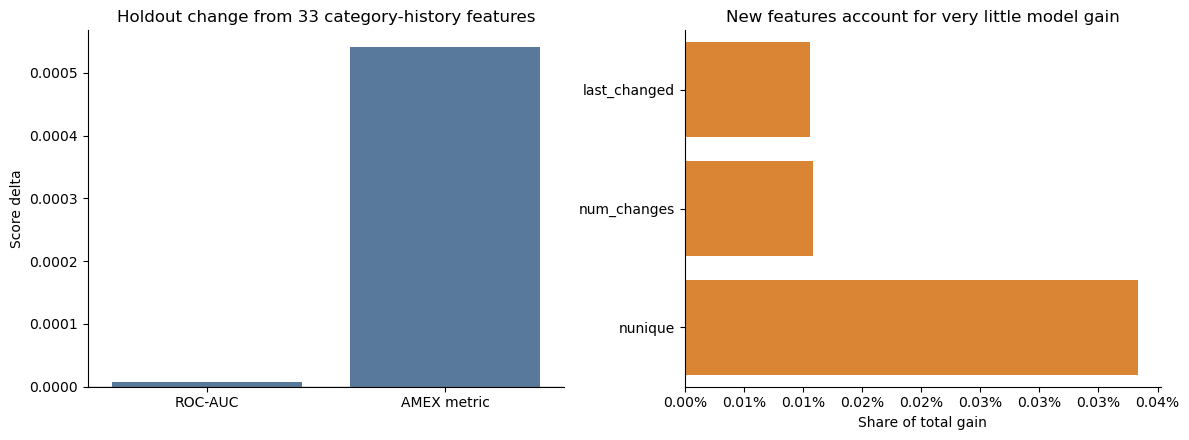

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Performance change and gain share of categorical-history families
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
metric_delta = pd.DataFrame({
    'metric': ['ROC-AUC', 'AMEX metric'],
    'delta': [result['roc_auc'] - previous['roc_auc'], result['amex_metric'] - previous['amex_metric']],
})
sns.barplot(data=metric_delta, x='metric', y='delta', color='#4C78A8', ax=axes[0])
axes[0].axhline(0, color='0.4', linewidth=1)
axes[0].set(title='Holdout change from 33 category-history features', xlabel='', ylabel='Score delta')

family_plot = summary.sort_values('gain_share')
sns.barplot(data=family_plot, y='categorical_feature_type', x='gain_share', color='#F58518', ax=axes[1])
axes[1].set(title='New features account for very little model gain', xlabel='Share of total gain', ylabel='')
axes[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
sns.despine()
plt.tight_layout()
plt.show()
